# DRAFT: Cálculo de NBI a partir del Censo 2023

En esta notebook, recreamos el índice de Necesidades Básicas Insatisfechas siguiendo la metodología del *Atlas Sociodemográfico y de la Desigualdad del Uruguay, Fascículo 1*, aplicada al Censo 2011. Es importante recalcular que esto se trata de un DRAFT, ya que aún los datos oficiales no están publicados, y son necesarios para nuestro análisis de accesibilidad.

Idea general:
- Son 6 dimensiones. Cada una vale 1 si hay carencia y 0 si no la hay.
- Las carencias se definen a nivel hogar. Todas las personas del hogar heredan la carencia.
- El NBI se calcula como la suma de las 6 dimensiones (de 0 a 6).

## Carga de datos


In [1]:
import pandas as pd
import geopandas as gpd
import folium
import numpy as np
from wbpyplot import wb_plot, colors
import matplotlib.pyplot as plt
from branca.colormap import LinearColormap
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
pd.options.display.float_format = "{:,.0f}".format

Cargamos sólo las columnas necesarias.

In [2]:
columnas = [
    "DEPARTAMENTO", "SECCION", "SEGMENTO",  # para recrear codseg
    "PERID", "ID_HOGAR", "VIVVO00", "SIT_CALLE", "W", "PERPH02", "ID_CENSO",
    "VIVDV01", "VIVDV02", "VIVDV03",      # materiales paredes, techo, piso
    "HOGHD00", "HOGPR01",                 # habitaciones (sin baño ni cocina) y personas del hogar
    "HOGSC01",                            # espacio para cocinar
    "VIVDV05", "VIVDV06",                 # origen y llegada del agua
    "HOGSH01", "HOGSH02", "HOGSH03",      # servicio higiénico
    "VIVDV07",                            # alumbrado eléctrico
    "HOGCA01", "HOGCE03", "HOGCE27",      # calefacción, heladera, calefón
    "PERNA01", "PERED01",                 # edad y asistencia educativa
]

censo = pd.read_csv("../data/population/personas_ext_07_2026.csv", usecols=columnas, encoding='latin-1')
censo["CODSEG"] = (censo["DEPARTAMENTO"].astype(int).astype(str).str.zfill(2) + censo["SECCION"].astype(int).astype(str).str.zfill(2) + censo["SEGMENTO"].astype(int).astype(str).str.zfill(3))
zonificacion = gpd.read_file("F:/WB/montevideo-brt/notebooks/output/zonas-a15-agg.gpkg")

print(censo.shape)
censo.head()

(3151118, 28)


,ID_CENSO,DEPARTAMENTO,SECCION,SEGMENTO,PERID,SIT_CALLE,VIVVO00,VIVDV01,VIVDV02,VIVDV03,...,HOGHD00,HOGCA01,HOGCE27,HOGCE03,HOGPR01,PERPH02,PERNA01,PERED01,W,CODSEG
0,571576,1,20,26,1,0,1,2,8,1,...,3,4,1,1,1,1,70,3,1,0120026
1,318716,1,20,35,1,0,1,1,2,1,...,3,2,1,1,2,2,35,3,1,0120035
2,1783062,1,20,35,2,0,1,1,2,1,...,3,2,1,1,2,1,2,7777,1,0120035
3,272874,1,20,35,1,0,1,1,7,1,...,3,4,1,1,3,2,48,3,1,0120035
4,2325405,1,20,35,2,0,1,1,7,1,...,3,4,1,1,3,2,16,1,1,0120035


## Filtrado de datos

El NBI se calcula solo para personas que viven en hogares particulares. Se sacan:
- las viviendas colectivas (`VIVVO00` = 2; el 1 es vivienda particular)
- las personas en situación de calle (`SIT_CALLE` = 1)

In [3]:
print("Antes del filtro:", len(censo))

censo = censo.loc[censo["VIVVO00"] == 1].copy()     # solo vivienda particular
censo = censo.loc[censo["SIT_CALLE"] != 1].copy()   # sin personas en situación de calle

print("\nDespués del filtro:", len(censo))

Antes del filtro: 3151118

Después del filtro: 3100348


# Cálculo de NBI

## Dimensión 1: Vivienda decorosa

Tiene 3 subindicadores. El hogar tiene NBI en vivienda si tiene carencia en al menos uno de ellos.

a) Materialidad: techo o paredes de desecho, o piso de tierra sin contrapiso.

In [4]:
paredes_desecho = censo["VIVDV01"] == 6     # materiales de desecho en paredes
techo_desecho   = censo["VIVDV02"] == 5     # materiales de desecho en techo
piso_tierra     = censo["VIVDV03"] == 4     # tierra sin piso ni contrapiso

censo["nbi_materialidad"] = (paredes_desecho | techo_desecho | piso_tierra).astype(int)
censo["nbi_materialidad"].value_counts()

nbi_materialidad
0    3090104
1      10244
Name: count, dtype: int64

b) Espacio habitable: hay hacinamiento si hay más de 2 personas por habitación, sin contar baño ni cocina.
- `HOGHD00` = cantidad de habitaciones (sin baños ni cocinas)
- `HOGPR01` = cantidad de personas que habitan el hogar

Antes de usar `HOGPR01`, se compara con la cantidad de filas por hogar para ver que coincidan.

In [5]:
# chequeo
filas_por_hogar = censo.groupby("ID_HOGAR")["PERID"].transform("size")
print("% de filas donde HOGPR01 coincide con las filas del hogar:", (censo["HOGPR01"] == filas_por_hogar).mean() * 100)

print("Hogares con 0 habitaciones:", (censo["HOGHD00"] == 0).sum())
print("Habitaciones vacías:", censo["HOGHD00"].isna().sum())

% de filas donde HOGPR01 coincide con las filas del hogar: 99.99948392890089
Hogares con 0 habitaciones: 0
Habitaciones vacías: 0


In [6]:
censo["personas_por_habitacion"] = censo["HOGPR01"] / censo["HOGHD00"]
censo["nbi_hacinamiento"] = (censo["personas_por_habitacion"] > 2).astype(int)
censo["nbi_hacinamiento"].value_counts()

nbi_hacinamiento
0    2902086
1     198262
Name: count, dtype: int64

c) Espacio apropiado para cocinar: el código 3 significa que no tiene.

In [7]:
censo["nbi_cocina"] = (censo["HOGSC01"] == 3).astype(int)
censo["nbi_cocina"].value_counts()

nbi_cocina
0    3036992
1      63356
Name: count, dtype: int64

A continuación, combinamos los tres indicadores. Alcanza con que tenga uno para que el hogar tenga NBI en vivienda decorosa.

In [8]:
censo["nbi_vivienda"] = ((censo["nbi_materialidad"] == 1) | (censo["nbi_hacinamiento"] == 1) | (censo["nbi_cocina"] == 1)).astype(int)
censo["nbi_vivienda"].value_counts()

nbi_vivienda
0    2853565
1     246783
Name: count, dtype: int64

## Dimensión 2: Abastecimiento de agua potable
NBI si el agua no llega por cañería dentro de la vivienda (`VIVDV06` = 2, 3 o 4) o si el origen no es red general ni pozo surgente protegido (`VIVDV05` = 3, 4, 5, 6 o 7).

In [9]:
agua_no_caneria = censo["VIVDV06"].isin([2, 3, 4])
agua_origen_mal = censo["VIVDV05"].isin([3, 4, 5, 6, 7])

censo["nbi_agua"] = (agua_no_caneria | agua_origen_mal).astype(int)
censo["nbi_agua"].value_counts()

nbi_agua
0    2933545
1     166803
Name: count, dtype: int64

## Dimensión 3: Servicio higiénico
NBI si no tiene baño (`HOGSH01` = 3), o el baño no es de uso exclusivo (`HOGSH02` = 2), o la evacuación no es a red general, fosa séptica o pozo negro (`HOGSH03` = 3 o 4).

In [10]:
sin_bano = censo["HOGSH01"] == 3
bano_compartido = censo["HOGSH02"] == 2
evacuacion_mala = censo["HOGSH03"].isin([3, 4])

censo["nbi_sanitario"] = (sin_bano | bano_compartido | evacuacion_mala).astype(int)
censo["nbi_sanitario"].value_counts()

nbi_sanitario
0    3034930
1      65418
Name: count, dtype: int64

## Dimensión 4: Energía eléctrica
NBI si no tiene ningún medio de alumbrado eléctrico (`VIVDV07` = 6).

In [11]:
censo["nbi_energia"] = (censo["VIVDV07"] == 6).astype(int)
censo["nbi_energia"].value_counts()

nbi_energia
0    3091329
1       9019
Name: count, dtype: int64

## Dimensión 5: Artefactos básicos de confort
NBI si al hogar le falta alguno de estos tres: calefacción (`HOGCA01` = 9, no tiene), heladera o freezer (`HOGCE03` = 2, no tiene), calefón o similar (`HOGCE27` = 2, no tiene).

In [12]:
sin_calefaccion = censo["HOGCA01"] == 9
sin_heladera    = censo["HOGCE03"] == 2
sin_calefon     = censo["HOGCE27"] == 2

censo["nbi_confort"] = (sin_calefaccion | sin_heladera | sin_calefon).astype(int)
censo["nbi_confort"].value_counts()

nbi_confort
0    2557354
1     542994
Name: count, dtype: int64

## Dimensión 6: Educación

Si en el hogar habita al menos una persona entre 4 y 17 años que no asiste a un centro educativo (`PERED01` = 3 o 4), todo el hogar tiene NBI en educación.

In [13]:
tiene_4_a_17 = (censo["PERNA01"] >= 4) & (censo["PERNA01"] <= 17)
no_asiste = censo["PERED01"].isin([3, 4])

censo["nino_no_asiste"] = (tiene_4_a_17 & no_asiste).astype(int)

# si alguien del hogar no asiste, todo el hogar queda con 1
censo["nbi_educacion"] = censo.groupby("ID_HOGAR")["nino_no_asiste"].transform("max")
censo["nbi_educacion"].value_counts()

nbi_educacion
0    3067622
1      32710
Name: count, dtype: int64

## NBI final
Se suman las 6 dimensiones. El resultado va de 0 a 6.

In [14]:
dimensiones = ["nbi_vivienda", "nbi_agua", "nbi_sanitario", "nbi_energia", "nbi_confort", "nbi_educacion"]

censo["NBI"] = censo[dimensiones].sum(axis=1)

print("% de personas con cada carencia:")
print((censo[dimensiones].mean() * 100).round(2))

% de personas con cada carencia:
nbi_vivienda     8
nbi_agua         5
nbi_sanitario    2
nbi_energia      0
nbi_confort     18
nbi_educacion    1
dtype: float64


In [15]:
csv_nbi = pd.DataFrame({
    "ID_CENSO": censo["ID_CENSO"],
    "ID_HOGAR": censo["ID_HOGAR"],
    "CODSEG": censo["CODSEG"],
    "W": censo["W"],
    "tiene_nbi": (censo["NBI"] >= 1).astype(int),
    "NBI": censo["NBI"],
})

csv_nbi.to_csv("output/personas_nbi.csv", index=False)

## NBI por zona

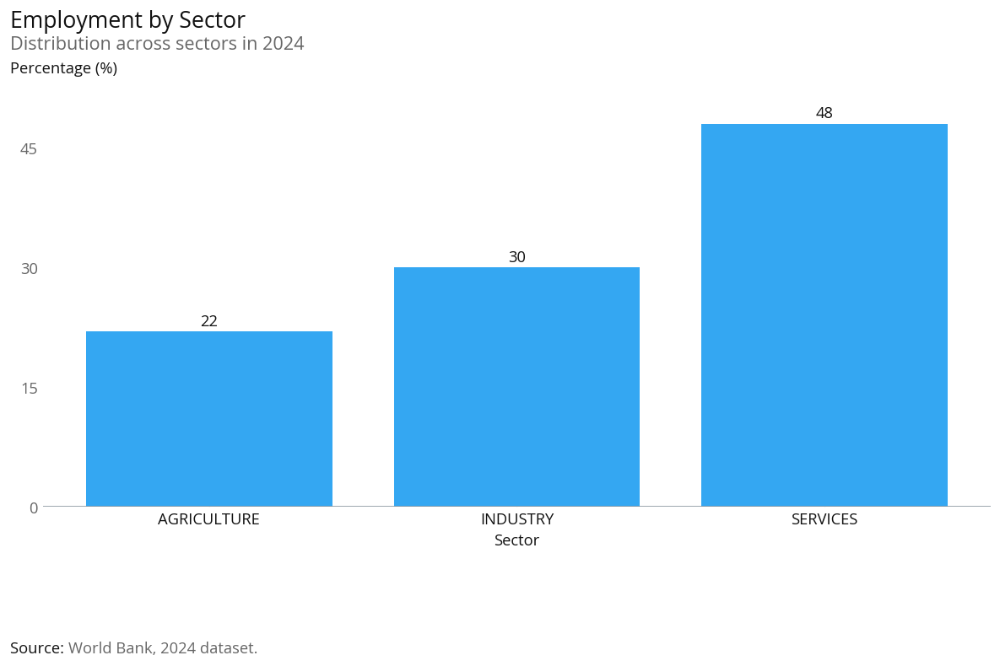

In [16]:
#add this to get the format only
from wbpyplot import wb_plot
@wb_plot(
    title="Employment by Sector",
    subtitle="Distribution across sectors in 2024",
    note=[("Source:", "World Bank, 2024 dataset.")],
)
def bar_plot(axs):
    sectors = ["Agriculture", "Industry", "Services"]
    values = [22, 30, 48]

    ax = axs[0]
    bars = ax.bar(sectors, values, label="Share of employment")

    ax.set_ylabel("Percentage (%)")
    ax.set_xlabel("Sector")


bar_plot()

El siguiente mapa muestra el porcentaje de población con al menos una NBI en cada zona de la zonificación. 

In [17]:
stops_8_octubre = gpd.read_file("../data/new-infrastructure/Paradas troncal 8 de octubre.kmz", driver="KML")
stops_italia = gpd.read_file("../data/new-infrastructure/Paradas Troncal Av. Italia.kmz", driver="KML")

In [19]:
segmentos = zonificacion[["poligono_id", "CODSEG"]].copy()
segmentos["CODSEG"] = segmentos["CODSEG"].str.split(",")
segmentos = segmentos.explode("CODSEG")
segmentos["CODSEG"] = segmentos["CODSEG"].str.strip()

censo_zonas = censo.merge(segmentos, on="CODSEG", how="inner")

censo_zonas["tiene_nbi"] = (censo_zonas["NBI"] >= 1).astype(int)
censo_zonas["tiene_2_o_mas"] = (censo_zonas["NBI"] >= 2).astype(int)

indicadores = ["tiene_nbi", "tiene_2_o_mas", "NBI"] + dimensiones

ponderado = censo_zonas[indicadores].mul(censo_zonas["W"], axis=0)
ponderado["poligono_id"] = censo_zonas["poligono_id"]
suma = ponderado.groupby("poligono_id").sum()

resultado = pd.DataFrame({"poblacion": censo_zonas.groupby("poligono_id")["W"].sum(), "n_encuestados": censo_zonas.groupby("poligono_id").size()})

for c in indicadores:
    resultado[c] = suma[c] / resultado["poblacion"]

cols_pct = ["tiene_nbi", "tiene_2_o_mas"] + dimensiones
resultado[cols_pct] *= 100

resultado = resultado.rename(columns={
    "tiene_nbi": "pct_nbi",
    "tiene_2_o_mas": "pct_nbi_2mas",
    "NBI": "nbi_medio"
})

resultado[["pct_nbi", "pct_nbi_2mas"] + dimensiones] = resultado[["pct_nbi", "pct_nbi_2mas"] + dimensiones].round(2)
resultado["nbi_medio"] = resultado["nbi_medio"].round(2)
resultado["poblacion"] = resultado["poblacion"].round().astype(int)

zonificacion = zonificacion.drop(columns=["poblacion"], errors="ignore")

mapa = zonificacion.merge(
    resultado,
    left_on="poligono_id",
    right_index=True,
    how="left"
).to_crs(epsg=4326)

bins = [0, 10, 20, 30, 40, float("inf")]
labels = ["0–10%", "10–20%", "20–30%", "30–40%", ">40%"]

mapa["nbi_cat"] = pd.cut(
    mapa["pct_nbi"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

legend_html = """
<div style="
    position: fixed;
    bottom: 30px;
    left: 30px;
    z-index: 9999;
    background-color: white;
    border: 1px solid grey;
    border-radius: 4px;
    padding: 10px;
    font-size: 13px;
">
    <b>Paradas</b><br>
    <span style="color: #002244;">●</span> Paradas 8 de Octubre<br>
    <span style="color: #009FDA;">●</span> Paradas Av. Italia
</div>
"""

mapa_interactivo = mapa.explore(
    column="nbi_cat",
    cmap="YlOrRd",
    categorical=True,
    tooltip=[
        "poligono_id",
        "pct_nbi",
        "pct_nbi_2mas",
        "nbi_medio",
        "poblacion",
        "n_encuestados"
    ],
    tooltip_kwds={"aliases": [
        "Zona",
        "% con NBI",
        "% con +2 NBI",
        "NBI promedio",
        "Población",
        "Encuestados"
    ]},
    legend=True,
    style_kwds={"weight": 0.5, "color": "white"},
    tiles="OpenStreetMap"
)

mapa_interactivo = stops_8_octubre.to_crs(epsg=4326).explore(m=mapa_interactivo, color="#002244", name="Paradas 8 de Octubre")
mapa_interactivo = stops_italia.to_crs(epsg=4326).explore(m=mapa_interactivo, color="#009FDA", name="Paradas Av. Italia")

folium.LayerControl().add_to(mapa_interactivo)
mapa_interactivo.get_root().html.add_child(folium.Element(legend_html))

display(mapa_interactivo)

In [21]:
cores = zonificacion.loc[zonificacion["tipo_zona"] == "Core"].copy()

segmentos = cores[["poligono_id", "CODSEG"]].copy()
segmentos["CODSEG"] = segmentos["CODSEG"].str.split(",")
segmentos = segmentos.explode("CODSEG")
segmentos["CODSEG"] = segmentos["CODSEG"].str.strip()

censo_cores = censo.merge(segmentos, on="CODSEG", how="inner")

tabla_cores = censo_cores.groupby("poligono_id").apply(lambda x: pd.Series({"poblacion": x["W"].sum(), "poblacion_nbi": x.loc[x["NBI"] >= 1, "W"].sum()}), include_groups=False)

tabla_cores["pct_nbi"] = (tabla_cores["poblacion_nbi"] / tabla_cores["poblacion"] * 100)
cores = cores.merge(tabla_cores, on="poligono_id", how="left")

Mapa estático que muestra el porcentaje de población con al menos una NBI en las zonas Core de la zonificación.

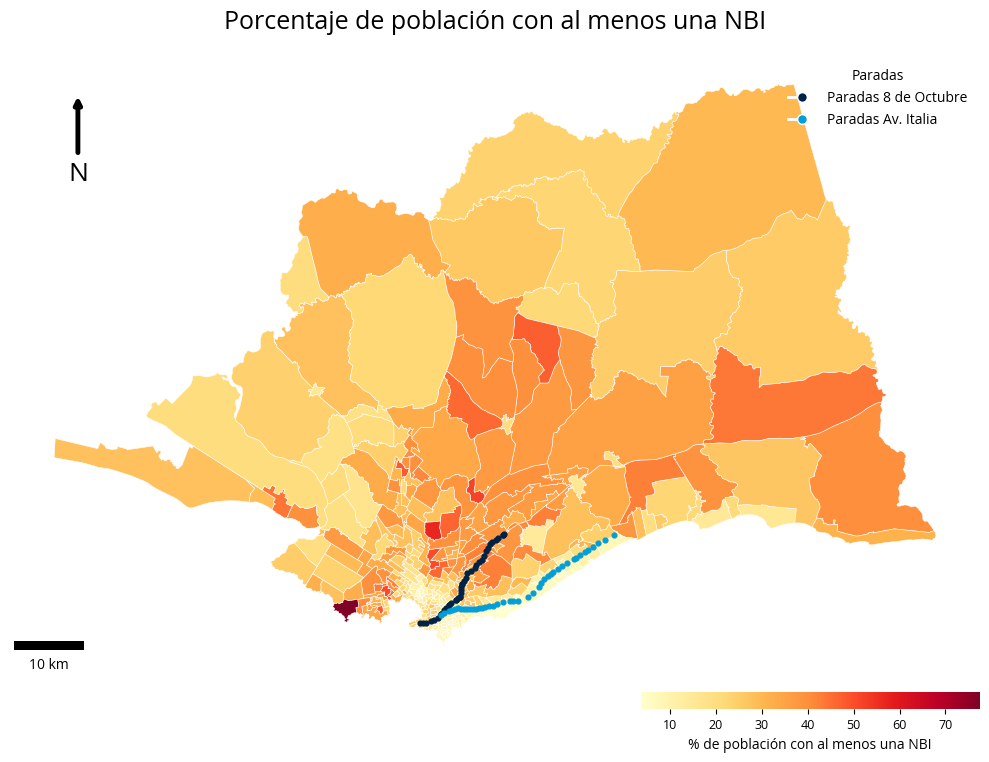

In [22]:
from matplotlib_scalebar.scalebar import ScaleBar
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(10, 10))
cores.plot(column="pct_nbi", cmap="YlOrRd", linewidth=0.4, edgecolor="white", ax=ax)
stops_8_octubre.to_crs(cores.crs).plot(ax=ax, color="#002244", markersize=12, zorder=3)
stops_italia.to_crs(cores.crs).plot(ax=ax, color="#009FDA", markersize=12, zorder=3)

ax.set_title("Porcentaje de población con al menos una NBI", fontsize=18, fontweight="bold", pad=20)

sm = ScalarMappable(norm=Normalize(vmin=cores["pct_nbi"].min(), vmax=cores["pct_nbi"].max()), cmap="YlOrRd")
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.025, pad=0.01, shrink=0.35, anchor=(1, 0))
cbar.set_label("% de población con al menos una NBI", fontsize=10)
cbar.ax.tick_params(labelsize=9)

ax.annotate("", xy=(0.07, 0.94), xytext=(0.07, 0.84), xycoords="axes fraction", arrowprops=dict(arrowstyle="-|>", lw=3.5, color="black"))
ax.text(0.07, 0.81, "N", transform=ax.transAxes, ha="center", va="center", fontsize=19, fontweight="black")
ax.add_artist(ScaleBar(1, units="m", dimension="si-length", location="lower left", length_fraction=0.10, height_fraction=0.015, box_alpha=0.8))

ax.legend(handles=[
    Line2D([0], [0], marker="o", color="w", label="Paradas 8 de Octubre", markerfacecolor="#002244", markersize=7),
    Line2D([0], [0], marker="o", color="w", label="Paradas Av. Italia", markerfacecolor="#009FDA", markersize=7)
], title="Paradas", loc="upper right")

ax.axis("off")
plt.tight_layout()
plt.show()

La misma idea, con un mapa interactivo.

In [23]:
cores_wgs = cores.to_crs(4326).copy()

vmin = cores["pct_nbi"].min()
vmax = cores["pct_nbi"].max()

colormap = LinearColormap(colors=["#ffffcc", "#ffeda0", "#feb24c", "#fd8d3c", "#f03b20", "#bd0026"], vmin=vmin, vmax=vmax, caption="% de población con al menos una NBI")
colormap.caption_font_size = 16

m = folium.Map(location=[-34.88, -56.16], zoom_start=11, tiles="OpenStreetMap")

folium.GeoJson(
    cores_wgs.to_json(),
    style_function=lambda feature: {
        "fillColor": (
            "#cccccc"
            if feature["properties"]["pct_nbi"] is None
            else colormap(feature["properties"]["pct_nbi"])
        ),
        "color": "white",
        "weight": 0.5,
        "fillOpacity": 0.75
    },
    highlight_function=lambda feature: {
        "weight": 2,
        "color": "black",
        "fillOpacity": 0.85
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["poligono_id", "pct_nbi", "poblacion", "poblacion_nbi"],
        aliases=["Zona", "% con al menos una NBI", "Población", "Población con NBI"],
        localize=True,
        sticky=False
    )
).add_to(m)

colormap.add_to(m)
stops_8_octubre.to_crs(4326).explore(m=m, color="#002244", name="Paradas 8 de Octubre")
stops_italia.to_crs(4326).explore(m=m, color="#009FDA", name="Paradas Av. Italia")


folium.LayerControl().add_to(m)
m.get_root().html.add_child(folium.Element(legend_html))

m

In [21]:
sin_zona = ~censo["CODSEG"].isin(segmentos["CODSEG"])
print("Personas sin zona:", sin_zona.sum(), f"({sin_zona.mean()*100:.1f}%)")

Personas sin zona: 1343662 (43.3%)


## Distribución de personas según presencia de NBI

In [22]:
def calcular_nbi_personas(df):
    hombres = df["PERPH02"] == 1
    mujeres = df["PERPH02"] == 2
    nbs = df["NBI"] == 0
    nbi = df["NBI"] >= 1

    tabla = pd.DataFrame({
        "Hombres": [
            df.loc[hombres & nbs, "W"].sum(),
            df.loc[hombres & nbi, "W"].sum(),
            df.loc[hombres, "W"].sum()],
        "Mujeres": [
            df.loc[mujeres & nbs, "W"].sum(),
            df.loc[mujeres & nbi, "W"].sum(),
            df.loc[mujeres, "W"].sum()]
    }, index=["NBS", "Al menos una NBI", "Total"])

    tabla["Total"] = tabla["Hombres"] + tabla["Mujeres"]
    tabla["Hombres %"] = tabla["Hombres"] / tabla.loc["Total", "Hombres"] * 100
    tabla["Mujeres %"] = tabla["Mujeres"] / tabla.loc["Total", "Mujeres"] * 100
    tabla["Total %"] = tabla["Total"] / tabla.loc["Total", "Total"] * 100
    return tabla


tabla_nbi_uruguay = calcular_nbi_personas(censo)
tabla_nbi_zonas = calcular_nbi_personas(censo_zonas)

print("Todo Uruguay")
display(tabla_nbi_uruguay)

print("Nuestra zonificación")
display(tabla_nbi_zonas)

Todo Uruguay


,Hombres,Mujeres,Total,Hombres %,Mujeres %,Total %
NBS,"1,206,417","1,319,571","2,525,988",73,74,73
Al menos una NBI,"455,454","464,834","920,288",27,26,27
Total,"1,661,872","1,784,405","3,446,277",100,100,100


Nuestra zonificación


,Hombres,Mujeres,Total,Hombres %,Mujeres %,Total %
NBS,"949,956","1,047,664","1,997,619",75,76,75
Al menos una NBI,"323,836","333,049","656,885",25,24,25
Total,"1,273,792","1,380,712","2,654,504",100,100,100


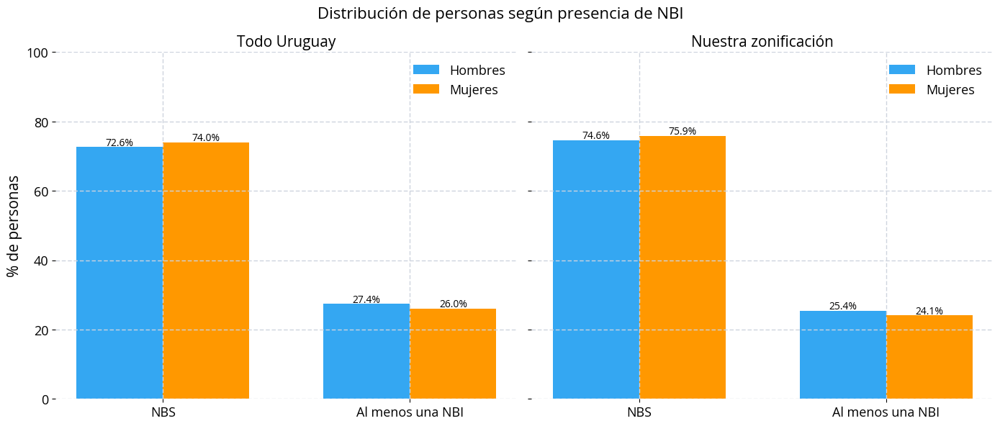

In [23]:
plt.rcParams.update({"axes.titlesize": 15, "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13,})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

x = np.arange(2)
width = 0.35
categorias = ["NBS", "Al menos una NBI"]

# Todo Uruguay
ax1.bar(x - width / 2, tabla_nbi_uruguay.loc[categorias, "Hombres %"], width, label="Hombres")
ax1.bar(x + width / 2,tabla_nbi_uruguay.loc[categorias, "Mujeres %"], width, label="Mujeres")

ax1.set_title("Todo Uruguay")
ax1.set_ylabel("% de personas")
ax1.set_xticks(x)
ax1.set_xticklabels(categorias)
ax1.legend()

# Nuestra zonificación
ax2.bar(x - width / 2, tabla_nbi_zonas.loc[categorias, "Hombres %"], width, label="Hombres")
ax2.bar(x + width / 2, tabla_nbi_zonas.loc[categorias, "Mujeres %"], width, label="Mujeres")

ax2.set_title("Nuestra zonificación")
ax2.set_xticks(x)
ax2.set_xticklabels(categorias)
ax2.legend()

for ax, tabla in [(ax1, tabla_nbi_uruguay), (ax2, tabla_nbi_zonas)]:
    for i, categoria in enumerate(categorias):
        hombres = tabla.loc[categoria, "Hombres %"]
        mujeres = tabla.loc[categoria, "Mujeres %"]

        ax.text(
            i - width / 2,
            hombres + 0.5,
            f"{hombres:.1f}%",
            ha="center"
        )
        ax.text(
            i + width / 2,
            mujeres + 0.5,
            f"{mujeres:.1f}%",
            ha="center"
        )

ax1.set_ylim(0, 100)

fig.suptitle("Distribución de personas según presencia de NBI", fontsize=16)

plt.tight_layout()
plt.show()

## Distribución de hogares según presencia de NBI

In [24]:
def calcular_nbi_hogares(df):
    hogares = df.drop_duplicates("ID_HOGAR").copy()

    tabla = pd.DataFrame({
        "Casos": [
            hogares.loc[hogares["NBI"] == 0, "ID_HOGAR"].nunique(),
            hogares.loc[hogares["NBI"] >= 1, "ID_HOGAR"].nunique(),
            hogares["ID_HOGAR"].nunique()
        ]
    }, index=["NBS", "Al menos una NBI", "Total"])

    tabla["%"] = tabla["Casos"] / tabla.loc["Total", "Casos"] * 100

    return tabla


tabla_hogares_uruguay = calcular_nbi_hogares(censo)
tabla_hogares_zonas = calcular_nbi_hogares(censo_zonas)

print("Todo Uruguay")
display(tabla_hogares_uruguay)
print("Nuestra zonificación")
display(tabla_hogares_zonas)

Todo Uruguay


,Casos,%
NBS,956892,76
Al menos una NBI,295101,24
Total,1251993,100


Nuestra zonificación


,Casos,%
NBS,771215,78
Al menos una NBI,216278,22
Total,987493,100


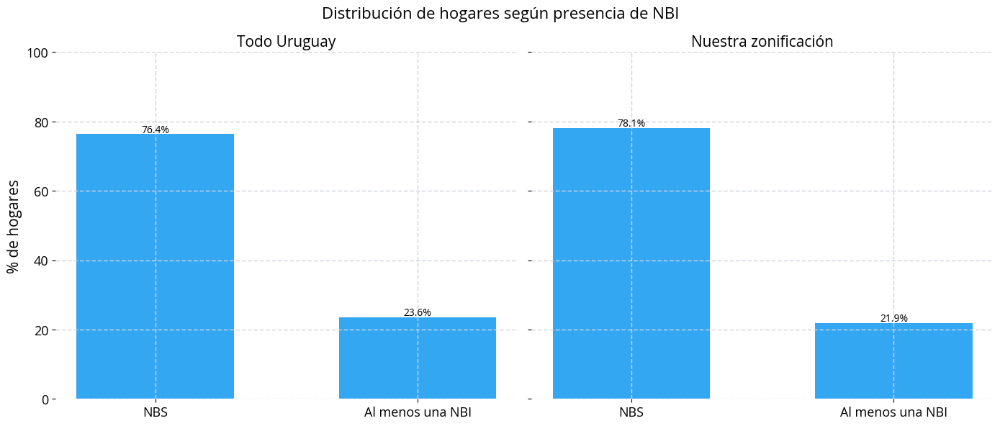

In [25]:
plt.rcParams.update({"axes.titlesize": 15,"axes.labelsize": 15,"xtick.labelsize": 13,"ytick.labelsize": 13,})

fig, (ax1, ax2) = plt.subplots(1, 2,figsize=(14, 6), sharex=True, sharey=True)

x = np.arange(2)

# Todo Uruguay
ax1.bar(x, tabla_hogares_uruguay.loc[["NBS", "Al menos una NBI"], "%"], width=0.6)
ax1.set_title("Todo Uruguay")
ax1.set_ylabel("% de hogares")
ax1.set_xticks(x)
ax1.set_xticklabels(["NBS", "Al menos una NBI"])

# Nuestra zonificación
ax2.bar(x, tabla_hogares_zonas.loc[["NBS", "Al menos una NBI"], "%"], width=0.6)
ax2.set_title("Nuestra zonificación")
ax2.set_xticks(x)
ax2.set_xticklabels(["NBS", "Al menos una NBI"])

for ax, tabla in [(ax1, tabla_hogares_uruguay), (ax2, tabla_hogares_zonas)]:
    for i, categoria in enumerate(["NBS", "Al menos una NBI"]):
        valor = tabla.loc[categoria, "%"]
        ax.text(
            i,
            valor + 0.5,
            f"{valor:.1f}%",
            ha="center")

ax1.set_ylim(0, 100)

fig.suptitle("Distribución de hogares según presencia de NBI", fontsize=16)
plt.tight_layout()
plt.show()

## Distribución de personas según cantidad de NBI

In [26]:
def calcular_nbi_por_sexo(df):
    hombres = df["PERPH02"] == 1
    mujeres = df["PERPH02"] == 2

    categorias = {"NBS": df["NBI"] == 0,"Una NBI": df["NBI"] == 1,"Dos NBI": df["NBI"] == 2,"Tres y más NBI": df["NBI"] >= 3}

    tabla = pd.DataFrame({
        "Hombres": [
            df.loc[hombres & condicion, "W"].sum()
            for condicion in categorias.values()
        ],
        "Mujeres": [
            df.loc[mujeres & condicion, "W"].sum()
            for condicion in categorias.values()
        ]
    }, index=categorias.keys())

    tabla["Hombres %"] = tabla["Hombres"] / tabla["Hombres"].sum() * 100
    tabla["Mujeres %"] = tabla["Mujeres"] / tabla["Mujeres"].sum() * 100

    return tabla

tabla_uruguay = calcular_nbi_por_sexo(censo)
tabla_zonas = calcular_nbi_por_sexo(censo_zonas)

print("Todo Uruguay")
display(tabla_uruguay)

print("Nuestra zonificación")
display(tabla_zonas)

Todo Uruguay


,Hombres,Mujeres,Hombres %,Mujeres %
NBS,"1,206,417","1,319,571",73,74
Una NBI,"337,381","349,621",20,20
Dos NBI,"84,108","85,516",5,5
Tres y más NBI,"33,965","29,697",2,2


Nuestra zonificación


,Hombres,Mujeres,Hombres %,Mujeres %
NBS,"949,956","1,047,664",75,76
Una NBI,"242,610","252,683",19,18
Dos NBI,"59,116","60,557",5,4
Tres y más NBI,"22,110","19,808",2,1


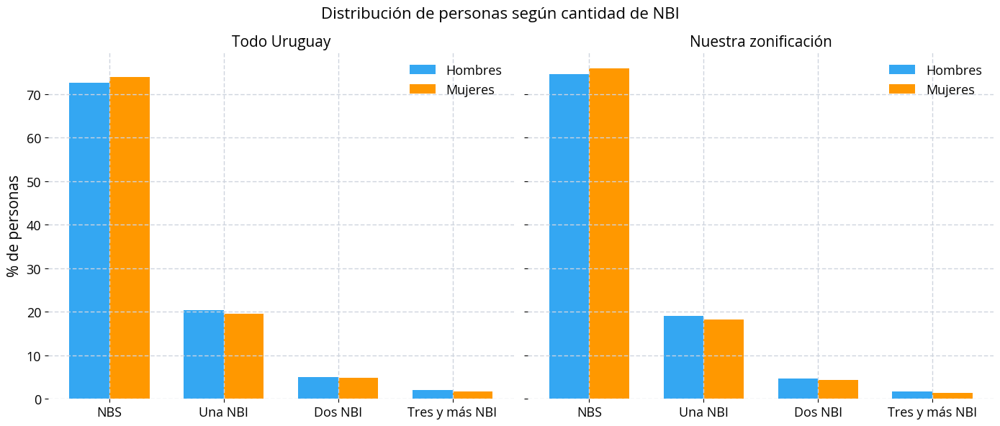

In [27]:
colors_wbplot = colors.PALETTES['wb_gender']
plt.rcParams.update({"axes.titlesize": 15, "axes.labelsize": 15, "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 13,})

fig, (ax1, ax2) = plt.subplots( 1, 2, figsize=(14, 6), sharex=True, sharey=True
)

x = np.arange(4)
width = 0.35

# Todo Uruguay
ax1.bar(x - width / 2, tabla_uruguay["Hombres %"], width, label="Hombres")

ax1.bar( x + width / 2, tabla_uruguay["Mujeres %"], width, label="Mujeres")

ax1.set_title("Todo Uruguay")
ax1.set_ylabel("% de personas")
ax1.set_xticks(x)
ax1.set_xticklabels(tabla_uruguay.index)
ax1.legend()

# Nuestra zonificación
ax2.bar(x - width / 2, tabla_zonas["Hombres %"], width, label="Hombres")
ax2.bar(x + width / 2, tabla_zonas["Mujeres %"], width, label="Mujeres")
ax2.set_title("Nuestra zonificación")
ax2.set_xticks(x)
ax2.set_xticklabels(tabla_zonas.index)
ax2.legend()

fig.suptitle("Distribución de personas según cantidad de NBI", fontsize=16)
plt.tight_layout()
plt.show()